<img src="https://www.hazfundacion.org/wp-content/uploads/2022/11/U-Carlos-III.png" width="300" alt="Universidad Carlos III de Madrid">

**Máster Universitario en Robótica y Automatización**

Asignatura: Procesamiento de Imágenes por Computador

Curso: 2026-27

Autores:
- Anthony Manzueta Difo
- Stefan Oshchypok
- Marina Ruiz Izu

Proyecto: **Reconocimiento de ocupación de plazas de aparcamiento mediante fine-tuning de redes preentrenadas**

# Problema a tratar

## Motivación

Conocer la disponibilidad de plazas libres es útil para la gestión de los aparcamientos y para reducir el tiempo y el tráfico que genera la búsqueda de plaza. Con la ocupación en tiempo real, los conductores ahorran tiempo de búsqueda.

Desde el punto de vista empresarial, la visión por computador aprovecha las cámaras de seguridad ya instaladas. Evita el coste de un sensor por plaza (en torno a 300-600 $ por plaza en los sistemas tradicionales) y la obra asociada. Además de la ocupación en tiempo real, permite obtener datos de uso (ocupación por franja horaria, tiempos de estancia) que ayudan a dimensionar y optimizar el aparcamiento. En empresas con parking en sus oficinas, mejora la experiencia de los empleados y reduce el tiempo y las emisiones de la búsqueda de plaza.

## Objetivo

Detectar plazas de aparcamiento libres y ocupadas mediante una cámara exterior. Dada una imagen de aparcamiento, el sistema localiza cada plaza y la clasifica como libre u ocupada, devolviendo para cada una un valor de confianza.

# Etapa 1: Preparación del Dataset

Aqui vamos a procesar un dataset [MetaPKLot-Dataset](https://huggingface.co/datasets/RajChauhan2911/MetaPKLot-Dataset) para crear nuestro mas pequeño y adaptado al problema enforntado.

El nuevo dataset creado debe ser subido al nuevo repositorio de [HuggingFace](https://huggingface.co/datasets/StafLoker/Meta-PKLot-mini).

## Imports

In [1]:
#!pip install -q huggingface_hub

import glob
import json
import os
import tarfile
import pandas as pd
from collections import Counter

from huggingface_hub import snapshot_download

In [2]:
import sys

EN_COLAB = 'google.colab' in sys.modules
if EN_COLAB:
    ![ -d /content/pic-proyecto ] || git clone -q https://github.com/StafLoker/pic-proyecto /content/pic-proyecto
    sys.path.append('/content/pic-proyecto/src')
    DATA = '/content/data'
else:
    sys.path.append('../src')
    DATA = '../data'

from normalizar import construir_coco_mini, validar_coco, copiar_imagenes, exportar_yolo

## Config

In [3]:
CONFIG = {
    'dataset': {
        'source': {
            'repo': 'RajChauhan2911/MetaPKLot-Dataset',
            'path': f'{DATA}/MetaPKLot',
        },
        'mini': {
            'repo': 'StafLoker/Meta-PKLot-mini',
            'path':  f'{DATA}/Meta-PKLot-mini',
        },
    }
}

## Dataset

### Download

In [4]:
snapshot_download(
    repo_id=CONFIG['dataset']['source']['repo'],
    repo_type='dataset',
    local_dir=CONFIG['dataset']['source']['path'],
    token=os.environ.get('HF_TOKEN'),
)

source_path = CONFIG['dataset']['source']['path']
num_files = 0
total_bytes = 0

for root, _, files in os.walk(source_path):
    num_files += len(files)
    total_bytes += sum(os.path.getsize(os.path.join(root, f)) for f in files)

print(f"Dataset size: {total_bytes / 1024**3:.2f} GB ({num_files} files)")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 16604 files:   0%|          | 0/16604 [00:00<?, ?it/s]

Dataset size: 4.63 GB (49815 files)


### Estructura del Dataset: MetaPKLot
```
MetaPKLot/
├── PKLot/
├── CNRPark-EXT/
├── annotations/
│   ├── original/
│   │   ├── spots/
│   │   └── cars/
│   └── cropped/
├── removed_images/
├── non_working_days/
└── non_representative_days/
```
El dataset completo MetaPKLot junta 3 datasets (PKLot, CNRPark-EXT, PLds) que se hicieron en diferentes lugares y que se anotaron bajo el mismo formato. El dataset PLds no contiene fotos, solo anotaciones.
- PKLot/: Contiene las fotos en formato .jpg  de 3 aparcamientos ('PUCPR', 'UFPR04', 'UFPR05')
- CNRPark-EXT/: Contiene las fotos en formato .jpg  de 9 cámaras ('camera1',…,'camera9')
- annotations/: Las anotaciones comprimidas en '.tar.xz' con un JSON por cada aparcamiento o cámara.
    - original/: coordenadas sobre la imagen completa
        - spots/: anotaciones de plazas

Nota: Como PLds solo contiene anotaciones y no contiene imágenes, solo usamos imágenes de los otros dos datasets

### Estructura de las anotaciones del dataset original

#### COCO

Las anotaciones están en formato **COCO** (JSON). Un fichero COCO tiene cinco secciones principales:

```json
{
  "info": {}, // Información del dataset: versión, descripción, fecha, etc.
  "licenses": [], // Licencias de las imágenes.
  "images": [], // Información de cada imagen.
  "categories": [], // Clases de objetos que reconoce el modelo.
  "annotations": [] // Anotaciones de los objetos presentes en las imágenes.
}
```

#### MetaPKLot

MetaPKLot reúne tres datasets: **PKLot**, **CNRPark-EXT** y **PLds**. Todos siguen la estructura COCO y se reparten en `annotations/`:

```
annotations/{original,cropped}/{cars,spots}/<dataset>/<subset>_<tipo>.tar.xz
```

Cada `.tar.xz` contiene un único JSON con las secciones `categories`, `climates`, `images`, `annotations` e `info`.

- **`spots`:** plazas, con las categorías `0 = empty` y `1 = occupied`.
- **`cars`:** vehículos, con la categoría `1 = car`.
- **`climates`:** idéntico en los tres datasets: `0 Overcast`, `1 Cloudy`, `2 Sunny`, `3 Rainy`, `4 Snowy`, `5 Clearnight`.

Campos comunes de cada imagen (`images`):

```json
{
  "images": [
    {
      "id": 0,
      "file_name": "...", // Ruta relativa a la raíz del dataset
      "width": 0,
      "height": 0,
      "annotationsRectangle": [x, y, w, h], // Región con anotación completa: fuera de ella no hay negativos fiables
      "date": [año, mes, día],
      "time": [hora, minuto, segundo],
      "climate": 0, // id de `climates`
      "dataset": "...",
      "subset": "..."
    },
    ...
  ]
}
```

Campos comunes de cada anotación de plaza (`annotations` de `spots`):

```json
{
  "annotations": [
    {
      "id": 0,
      "image_id": 0, // Imagen a la que pertenece
      "category_id": 1, // 0 = empty, 1 = occupied
      "segmentation": [[x1, y1, x2, y2, ...]], // Polígono de la plaza
      "bbox": [x, y, w, h], // Esquina superior izquierda, ancho y alto
      "area": 0.0,
      "iscrowd": 0,
      "car_id": 0, // Vehículo que la ocupa (-1: ninguno, -2: algo que no es un coche)
      "best_rotated_rect": [[cx, cy], [w, h], ángulo] // Rectángulo rotado de la plaza
    },
    ...
  ]
}
```

A continuación, un registro real de plazas de cada dataset (`original/spots`, polígonos recortados).

#### PKLot

3 subsets (`pucpr`, `ufpr04`, `ufpr05`), 12 400 imágenes y 1 199 857 plazas. Sunny, Cloudy y Rainy.

```json
{
  "images": [
    {
      "id": 11000002330,
      "file_name": "PKLot/PUCPR/Sunny/2012-09-11/2012-09-11_15_16_58.jpg",
      "width": 1280, "height": 720,
      "annotationsRectangle": [0, 140, 1280, 580],
      "date": [2012, 9, 11], "time": [15, 16, 58],
      "climate": 2, "dataset": "pklot", "subset": "pucpr"
    },
    ...
  ],
  "annotations": [
    {
      "id": 11000000000,
      "image_id": 11000002330, // id de la imagen de `images`
      "category_id": 1,
      "segmentation": [[278, 230, 290, 186, 324, 185, 308, 230]],
      "bbox": [278, 185, 46, 45], "area": 1417.0, "iscrowd": 0,
      "car_id": 11000012277,
      "best_rotated_rect": [[299.03, 205.51], [32.27, 58.68], 14.93]
    },
    ...
  ]
}
```

- Imágenes de 1280×720 y coordenadas enteras.
- `annotationsRectangle` depende del subset: `[0, 140, 1280, 580]` en PUCPR y `[0, 0, 1280, 720]` en UFPR04.
- `car_id` negativo: `-1` en 656 269 plazas y `-2` en 106.

#### CNRPark-EXT

9 subsets (`camera1` … `camera9`), 4 073 imágenes y 165 530 plazas. Sunny, Overcast y Rainy.

```json
{
  "images": [
    {
      "id": 21000000403,
      "file_name": "CNRPark-EXT/camera1/SUNNY/2015-11-12/2015-11-12_07_09_00.jpg",
      "width": 1000, "height": 750,
      "annotationsRectangle": [78, 158, 922, 592],
      "date": [2015, 11, 12], "time": [7, 9, 0],
      "climate": 2, "dataset": "cnr", "subset": "camera1"
    },
    ...
  ],
  "annotations": [
    {
      "id": 21000000000,
      "image_id": 21000000403, // id de la imagen de `images`
      "category_id": 0,
      "segmentation": [[391.4, 328.6, 435.0, 357.4, 347.0, 419.5, 296.0, 392.4]],
      "bbox": [296.0, 328.6, 139.0, 90.9], "area": 5544.0, "iscrowd": 0,
      "car_id": -1,
      "best_rotated_rect": [[366.25, 376.02], [50.88, 135.0], 56.23]
    },
    ...
  ]
}
```

- Imágenes de 1000×750 y coordenadas decimales.
- La carpeta del clima va en mayúsculas (`SUNNY`).
- `car_id` negativo: `-1` en 78 009 plazas y `-2` en 32.

#### PLds

4 subsets (`isshk`, `qridr`, `vmlix`, `vxusd`), 8 188 imágenes y 104 728 plazas. Sunny, Overcast, Rainy, Snowy y Clearnight. **Las imágenes no están en disco, solo las anotaciones.**

```json
{
  "images": [
    {
      "id": 31000000000,
      "file_name": "PLds/isshk/Daytime/Snow/2016-02-18/isshk_0475.jpg",
      "width": 1920, "height": 1080,
      "annotationsRectangle": [432, 200, 1342, 910],
      "date": [2016, 2, 18], "time": [7, 30, 27],
      "climate": 4, "dataset": "plds", "subset": "isshk"
    },
    ...
  ],
  "annotations": [
    {
      "id": 31000000000,
      "image_id": 31000000000, // id de la imagen de `images`
      "category_id": 0,
      "segmentation": [[918.3, 915.1, 904.0, 1080.0, 1409.0, 1080.0, 1392.3, 919.1]],
      "bbox": [904.0, 915.1, 505.0, 164.9], "area": 79694.0, "iscrowd": 0,
      "car_id": -1,
      "best_rotated_rect": [[1156.5, 997.55], [505.0, 164.9], -0.0]
    },
    ...
  ]
}
```

- La resolución cambia según el subset: 1920×1080 en `isshk` y 1280×720 en `vmlix`.
- La ruta incluye `Daytime/Snow`, pero el campo `climate` dice `Snowy`.
- Coordenadas decimales. `car_id` negativo: solo `-1` (60 421 plazas).

#### Para unificar

- Los `id` llevan un prefijo por dataset (`11…`, `21…`, `31…`), así que se pueden juntar sin colisiones.
- El clima hay que leerlo de `climate`, no de la ruta: cambian la profundidad y las mayúsculas.
- `spots` y `cars` no comparten las mismas imágenes: sin coches anotados, la imagen no aparece en `cars`.
- La tabla «Climate Metadata» del `README.md` de MetaPKLot (ids 1-6, con `no_rain` y `undefined`) no coincide con los JSON (ids 0-5, con `Cloudy` y `Clearnight`). Hay que fiarse de `climates`.

#### `original` frente a `cropped`

Mismas imágenes y mismas anotaciones (`id`, `file_name`, `category_id`, `car_id`). Solo cambia la geometría: `cropped` está recortado a `annotationsRectangle`.

|                                             | `original`                        | `cropped`                                                     |
| ------------------------------------------- | --------------------------------- | ------------------------------------------------------------- |
| `width` / `height`                          | imagen completa                   | recorte (PUCPR: 1280×580 en vez de 1280×720)                  |
| `annotationsRectangle`                      | sí                                | no (salvo en `vmlix` y `vxusd`, donde empieza en `[0, 0, …]`) |
| `bbox`, `segmentation`, `best_rotated_rect` | coordenadas de la imagen completa | desplazadas al origen del recorte (PUCPR: `y` baja 140)       |
| `dataset` / `subset`                        | `pklot` / `pucpr`                 | `PKLot` / `pucpr_spots` (`vmlix` y `vxusd` no cambian)        |
| `file_name`                                 | imagen completa                   | **la misma ruta**                                             |

Las imágenes que hay en disco son las completas, y `file_name` de `cropped` apunta a ellas, así que sus coordenadas no encajan. Usaremos `original`.

En los subsets donde el recorte ya cubre toda la imagen (UFPR04, UFPR05, `camera2` … `camera8`) el tamaño no cambia, pero la `bbox` difiere en ±1 píxel (en PUCPR, `[278, 185, 46, 45]` frente a `[278, 45, 47, 46]`). No he comprobado cómo se calcula.

#### Carpetas auxiliares

- **`removed_images/`:** `pklot.txt` (17), `cnrpark-ext.txt` (205) y `plds.txt` (157). Rutas de imágenes eliminadas: corruptas en PKLot, mala iluminación en CNRPark-EXT, timestamps repetidos o zoom inesperado en PLds. El nº de imágenes de `spots` (12 400 y 4 073) coincide con los `.jpg` en disco.
- **`non_working_days/`:** un `days_ignore` por subset, con líneas como `2012-09-15 / Saturday`. Fines de semana y festivos.
- **`non_representative_days/`:** un `non_representative_days` por subset, con líneas como `2016-02-18 / day with low occupance`. Días sin trabajo, de poca duración o de poca ocupación. El README recomienda consultarlos al reproducir experimentos.
- **`readme_images/` y `tools/`:** ilustraciones del README y herramientas de marcado, validación y conversión de PLds. No se usan en el proyecto.

### Etiquetas disponibles

Para cada fichero de anotaciones se muestran sus secciones, sus categorías y cuántas anotaciones hay de cada una.

In [5]:
annotations_glob = os.path.join(CONFIG['dataset']['source']['path'], 'annotations', '**', '*.tar.xz')
annotation_files = sorted(glob.glob(annotations_glob, recursive=True))

if not annotation_files:
    raise FileNotFoundError(f"No annotation files found: {annotations_glob}")

for path in annotation_files:
    with tarfile.open(path, 'r:xz') as tar:
        member = next(m for m in tar if m.name.endswith('.json'))
        coco = json.load(tar.extractfile(member))

    category_names = {c['id']: c['name'] for c in coco['categories']}
    counts = Counter(category_names[a['category_id']] for a in coco['annotations'])

    print(os.path.relpath(path, CONFIG['dataset']['source']['path']))
    print(f"  sections:    {list(coco.keys())}")
    print(f"  images:      {len(coco['images'])}")
    print(f"  categories:  {category_names}")
    print(f"  annotations: {dict(counts)}")

annotations/cropped/cars/CNRPark-EXT/cnr-camera-1_cars.tar.xz
  sections:    ['categories', 'climates', 'images', 'annotations', 'info']
  images:      452
  categories:  {1: 'car'}
  annotations: {'car': 10630}
annotations/cropped/cars/CNRPark-EXT/cnr-camera-2_cars.tar.xz
  sections:    ['categories', 'climates', 'images', 'annotations', 'info']
  images:      457
  categories:  {1: 'car'}
  annotations: {'car': 4791}
annotations/cropped/cars/CNRPark-EXT/cnr-camera-3_cars.tar.xz
  sections:    ['categories', 'climates', 'images', 'annotations', 'info']
  images:      450
  categories:  {1: 'car'}
  annotations: {'car': 8129}
annotations/cropped/cars/CNRPark-EXT/cnr-camera-4_cars.tar.xz
  sections:    ['categories', 'climates', 'images', 'annotations', 'info']
  images:      449
  categories:  {1: 'car'}
  annotations: {'car': 10989}
annotations/cropped/cars/CNRPark-EXT/cnr-camera-5_cars.tar.xz
  sections:    ['categories', 'climates', 'images', 'annotations', 'info']
  images:      45

## Selección de los datos

### Tabla de imágenes
Creación de tabla con una fila por imagen a partir de annotations/original/spots.

In [6]:
# Creación de la tabla

## Buscamos los archivos .tar.xz en la carpeta de anotaciones
src=CONFIG['dataset']['source']['path']
spots_files_path=os.path.join(src, 'annotations', 'original', 'spots', '*', '*.tar.xz')
spots_files=glob.glob(spots_files_path)
spots_files=sorted(spots_files)

print(len(spots_files))
spots_files

16


['/content/data/MetaPKLot/annotations/original/spots/CNRPark-EXT/cnr-camera-1_spots.tar.xz',
 '/content/data/MetaPKLot/annotations/original/spots/CNRPark-EXT/cnr-camera-2_spots.tar.xz',
 '/content/data/MetaPKLot/annotations/original/spots/CNRPark-EXT/cnr-camera-3_spots.tar.xz',
 '/content/data/MetaPKLot/annotations/original/spots/CNRPark-EXT/cnr-camera-4_spots.tar.xz',
 '/content/data/MetaPKLot/annotations/original/spots/CNRPark-EXT/cnr-camera-5_spots.tar.xz',
 '/content/data/MetaPKLot/annotations/original/spots/CNRPark-EXT/cnr-camera-6_spots.tar.xz',
 '/content/data/MetaPKLot/annotations/original/spots/CNRPark-EXT/cnr-camera-7_spots.tar.xz',
 '/content/data/MetaPKLot/annotations/original/spots/CNRPark-EXT/cnr-camera-8_spots.tar.xz',
 '/content/data/MetaPKLot/annotations/original/spots/CNRPark-EXT/cnr-camera-9_spots.tar.xz',
 '/content/data/MetaPKLot/annotations/original/spots/PKLot/pucpr_spots.tar.xz',
 '/content/data/MetaPKLot/annotations/original/spots/PKLot/ufpr04_spots.tar.xz',
 '

Encontramos los 16 archivos de los cuales 9 corresponden a las cámaras del dataset CNRPark-EXT; 3 correponden a los parkings del dataset PKLot; y finalmente 4 corresponden al dataset PLds.

A continuación, leemos como ejemplo un archivo

In [7]:
path = spots_files[0]
print(path)

/content/data/MetaPKLot/annotations/original/spots/CNRPark-EXT/cnr-camera-1_spots.tar.xz


In [8]:
with tarfile.open(path, 'r:xz') as tar:
    member = next(m for m in tar if m.name.endswith('.json'))
    json_file = json.load(tar.extractfile(member))

json_file.keys()


dict_keys(['categories', 'climates', 'images', 'annotations', 'info'])

In [9]:
json_file['categories']

[{'id': 0, 'name': 'empty'}, {'id': 1, 'name': 'occupied'}]

In [10]:
json_file['climates']

[{'id': 0, 'name': 'Overcast'},
 {'id': 1, 'name': 'Cloudy'},
 {'id': 2, 'name': 'Sunny'},
 {'id': 3, 'name': 'Rainy'},
 {'id': 4, 'name': 'Snowy'},
 {'id': 5, 'name': 'Clearnight'}]

In [11]:
print(len(json_file['images']))
json_file['images'][0]

452


{'id': 21000000403,
 'file_name': 'CNRPark-EXT/camera1/SUNNY/2015-11-12/2015-11-12_07_09_00.jpg',
 'width': 1000,
 'height': 750,
 'annotationsRectangle': [78, 158, 922, 592],
 'date': [2015, 11, 12],
 'time': [7, 9, 0],
 'climate': 2,
 'dataset': 'cnr',
 'subset': 'camera1'}

In [12]:
print(len(json_file['annotations']))
json_file['annotations'][0]

15820


{'id': 21000000000,
 'image_id': 21000000403,
 'category_id': 0,
 'segmentation': [[391.4, 328.6, 435.0, 357.4, 347.0, 419.5, 296.0, 392.4]],
 'area': 5544.0,
 'bbox': [296.0, 328.6, 139.0, 90.9],
 'iscrowd': 0,
 'car_id': -1,
 'best_rotated_rect': [[366.2506408691406, 376.0224609375],
  [50.87796401977539, 134.99978637695312],
  56.22686004638672]}

In [13]:

filas=[]

for path in spots_files:
    with tarfile.open(path, 'r:xz') as tar:
        member = next(m for m in tar if m.name.endswith('.json'))
        json_file = json.load(tar.extractfile(member))

    # Contador de plazas libres y ocupadas por imagen
    conteo={} # Diccionario vacío donde se guarda {id_foto: [plazas_libres, plazas_ocupadas]}

    for spot in json_file['annotations']:
        id_foto=spot['image_id']
        estado=spot['category_id']

        if id_foto not in conteo:
            conteo[id_foto]=[0,0] # Inicializamos el contador de plazas

        if estado==1:
            conteo[id_foto][1]+=1 # Incremento de plazas ocupadas
        if estado==0:
            conteo[id_foto][0]+=1 # Incremento de plazas libres

    # Recorremos las imágenes de un archivo json
    for img in json_file['images']:
        id_foto=img['id']

        # Conteo número de plazas libres y ocupadas
        if id_foto in conteo:
            plazas_libres=conteo[id_foto][0]
            plazas_ocupadas = conteo[id_foto][1]
        else:
            plazas_libres = 0
            plazas_ocupadas = 0

        # Fecha en formato YYYY-MM-DD
        y=img['date'][0]
        m=img['date'][1]
        d=img['date'][2]
        fecha_texto=f'{y:04d}-{m:02d}-{d:02d}'

        # Clima
        climas={c['id']: c['name'] for c in json_file['climates']}

        fila={
            'image_id': img['id'],
            'file_name': img['file_name'],
            'dataset': img['dataset'],
            'subset': img['subset'],
            'fecha': fecha_texto,
            'hora': img['time'][0],
            'clima': climas[img['climate']],
            'plazas_libres': plazas_libres,
            'plazas_ocupadas': plazas_ocupadas,
            'plazas': plazas_libres + plazas_ocupadas
        }
        filas.append(fila)

tabla=pd.DataFrame(filas)
print(len(tabla))
tabla.head(5)

24661


,image_id,file_name,dataset,subset,fecha,hora,clima,plazas_libres,plazas_ocupadas,plazas
0,21000000403,CNRPark-EXT/camera1/SUNNY/2015-11-12/2015-11-1...,cnr,camera1,2015-11-12,7,Sunny,32,3,35
1,21000000393,CNRPark-EXT/camera1/SUNNY/2015-11-12/2015-11-1...,cnr,camera1,2015-11-12,7,Sunny,31,4,35
2,21000000400,CNRPark-EXT/camera1/SUNNY/2015-11-12/2015-11-1...,cnr,camera1,2015-11-12,8,Sunny,30,5,35
3,21000000411,CNRPark-EXT/camera1/SUNNY/2015-11-12/2015-11-1...,cnr,camera1,2015-11-12,8,Sunny,26,9,35
4,21000000396,CNRPark-EXT/camera1/SUNNY/2015-11-12/2015-11-1...,cnr,camera1,2015-11-12,9,Sunny,13,22,35


Agrupamos por dataset y subset para ver el número de imágenes y el número de plazas

In [14]:
resumen=tabla.groupby(['dataset', 'subset']).agg(
    imagenes=('image_id', 'count'),
    dias=('fecha', 'nunique'),
    plazas=('plazas', 'sum'),
    plazas_por_imagen=('plazas', 'mean'),
    libres=('plazas_libres', 'sum'),
    ocupadas=('plazas_ocupadas', 'sum'),
)
resumen['%_ocupadas'] = (100 * resumen['ocupadas'] / resumen['plazas']).round(1)
resumen['plazas_por_imagen'] = (resumen['plazas_por_imagen']).round(1)
resumen

imagenes  dias  plazas  plazas_por_imagen  libres  ocupadas  \
dataset subset                                                                 
cnr     camera1       452    23   15820               35.0    6651      9169   
        camera2       457    23    4570               10.0    1656      2914   
        camera3       452    23   10396               23.0    4521      5875   
        camera4       449    23   19307               43.0    8973     10334   
        camera5       454    23   24970               55.0   12002     12968   
        camera6       455    23   25025               55.0   12513     12512   
        camera7       455    23   24115               53.0   12144     11971   
        camera8       448    23   24640               55.0   11578     13062   
        camera9       451    23   16687               37.0    8003      8684   
pklot   pucpr        4474    37  872430              195.0  500280    372150   
        ufpr04       3791    30  137217               36.2   75152     62065   
        ufpr05       4135    33  190210               46.0   80839    109371   
plds    isshk        3664    48   43968               12.0   26794     17174   
        qridr        1000    18   14000               14.0    6133      7867   
        vmlix        2592    34   32780               12.6   17616     15164   
        vxusd         932    15   13980               15.0    9878      4102   

                 %_ocupadas  
dataset subset               
cnr     camera1        58.0  
        camera2        63.8  
        camera3        56.5  
        camera4        53.5  
        camera5        51.9  
        camera6        50.0  
        camera7        49.6  
        camera8        53.0  
        camera9        52.0  
pklot   pucpr          42.7  
        ufpr04         45.2  
        ufpr05         57.5  
plds    isshk          39.1  
        qridr          56.2  
        vmlix          46.3  
        vxusd          29.3

### Filtrar la tabla
1. Quitar dataset PLds porque las imágenes no están disponibles
2. Quitar imágenes sin plazas anotadas
3. Quitar imágenes de removed_images/

In [15]:
print(f"Antes de filtrar: {len(tabla)}")

Antes de filtrar: 24661


In [16]:
# Quitamos dataset PLds
tabla=tabla[tabla["dataset"]!="plds"]
print(f"Longitud de tabla después de quitar PLDS: {len(tabla)}")

# Quitamos imágenes sin plazas anotadas
tabla=tabla[tabla["plazas"]>0]
print(f"Longitud de tabla después de quitar imágenes sin plazas anotadas: {len(tabla)}")


Longitud de tabla después de quitar PLDS: 16473
Longitud de tabla después de quitar imágenes sin plazas anotadas: 16473


### Reparto de las imágenes
Para empezar, las 5,000 imágenes con las que vamos a trabajar se reparten de forma equitativa entre el dataset CNRPark-EXT y PKLot, es decir, 2,500 imágenes para cad dataset.
En el caso del dataset CNRPark-EXT, tenemos 9 subsets que corresponden a diferentes cámaras (de 1 a 9). Como cada cámara tiene un punto de vista diferente, escogemos alrededor de 278 fotos por cámara repartidas de forma equitativa entre las 9 cámaras.
En el caso del dataset PKLot, este está dividido en 3 subconjunto de datos (PUCPR, UFPR04, UFPR05). Dado que la cantidad de plazas por imagen de PUCPR es de 195 frente a 36 y 46 de los otros dos subconjuntos respectivamente, el reparto se va hacer de forma que cada subconjunto aporte la misma cantidad de plazas de parking:
- PUCPR: 235 imágenes
- UFPR04: 1,268 imágenes
- UFPR05: 997 imágenes

En resumen:

| Dataset | Subset | Imágenes disponibles | Plazas por imagen | **Imágenes seleccionadas** | % usado | Plazas aprox. |
|---|---|---:|---:|---:|---:|---:|
| **CNRPark-EXT** | camera1 | 452 | 35 | **278** | 61 % | 9.730 |
| | camera2 | 457 | 10 | **278** | 61 % | 2.780 |
| | camera3 | 452 | 23 | **278** | 61 % | 6.394 |
| | camera4 | 449 | 43 | **278** | 62 % | 11.954 |
| | camera5 | 454 | 55 | **278** | 61 % | 15.290 |
| | camera6 | 455 | 55 | **278** | 61 % | 15.290 |
| | camera7 | 455 | 53 | **278** | 61 % | 14.734 |
| | camera8 | 448 | 55 | **278** | 62 % | 15.290 |
| | camera9 | 451 | 37 | **276** | 61 % | 10.212 |
| | **Subtotal** | **4.073** | | **2.500** | **61 %** | **≈ 101.700** |
| **PKLot** | pucpr | 4.474 | 195 | **235** | 5 % | 45.825 |
| | ufpr04 | 3.791 | 36,2 | **1.268** | 33 % | 45.902 |
| | ufpr05 | 4.135 | 46 | **997** | 24 % | 45.862 |
| | **Subtotal** | **12.400** | | **2.500** | **20 %** | **≈ 137.600** |
| **Total** | | **16.473** | | **5.000** | **30 %** | **≈ 239.300** |


### Selección de las muestras para cada subset
En esta parte, vamos a coger todas las imágenes para cada subconjunto, agrupamos las imágenes por día, franja horaria y clima y seleccionamos al azar el mismo porcentaje de fotos.

In [17]:
# Definimos las franjas horarias: mañana, mediodia, tarde

def franja_horaria(hora):
    if hora<11:
        return 'mañana'
    elif hora<16:
        return 'mediodia'
    else:
        return 'tarde'

tabla['franja_horaria']=tabla['hora'].apply(franja_horaria)
pd.crosstab(tabla['subset'], tabla['franja_horaria'])

franja_horaria,mañana,mediodia,tarde
subset,,,
camera1,167,230,55
camera2,168,230,59
camera3,168,230,54
camera4,169,230,50
camera5,170,230,54
camera6,172,230,53
camera7,172,230,53
camera8,163,227,58
camera9,168,230,53


Veamos si hay diferentes climas en un día o si por cada día el clima es igual.

In [18]:
climas_por_dia = tabla.groupby(['subset', 'fecha'])['clima'].nunique()

print("Días con un solo clima:", (climas_por_dia == 1).sum(), "de", len(climas_por_dia))
print(f"Porcentaje: {(climas_por_dia == 1).sum() / len(climas_por_dia) * 100:.2f}%")

Días con un solo clima: 268 de 307
Porcentaje: 87.30%


In [19]:
# Reparto de imágenes para cada subconjunto del dataset

partes=[]

num_img_subset = { # Diccionario con el número de imágenes que queremos por cada subconjunto (Subset)
    # CNRPark-EXT
    'camera1': 278, 'camera2': 278, 'camera3': 278,
    'camera4': 278, 'camera5': 278, 'camera6': 278,
    'camera7': 278, 'camera8': 278, 'camera9': 276,
    # PKLot
    'pucpr': 235, 'ufpr04': 1268, 'ufpr05': 997,
}

for subset, n in num_img_subset.items():
    grupo=tabla[tabla['subset']==subset]
    frac=n/len(grupo)
    print(f"Cogemos {frac:.0%} de las imágenes del subset {subset}")

    # Creamos la muestra haciendo el reparto para cad fecha y franja horaria
    muestra = grupo.groupby(['fecha', 'franja_horaria', 'clima']).sample(frac=frac, random_state=99)

    if len(muestra)>n:
        muestra = muestra.sample(n=n, random_state=99)
    elif len(muestra)<n:
        restantes = grupo.drop(muestra.index)
        extra = restantes.sample(n=n - len(muestra), random_state=99)
        muestra = pd.concat([muestra, extra])

    partes.append(muestra)

tabla_muestreada = pd.concat(partes)
print("Seleccionadas:", len(tabla_muestreada))
tabla_muestreada.head(5)


Cogemos 62% de las imágenes del subset camera1
Cogemos 61% de las imágenes del subset camera2
Cogemos 62% de las imágenes del subset camera3
Cogemos 62% de las imágenes del subset camera4
Cogemos 61% de las imágenes del subset camera5
Cogemos 61% de las imágenes del subset camera6
Cogemos 61% de las imágenes del subset camera7
Cogemos 62% de las imágenes del subset camera8
Cogemos 61% de las imágenes del subset camera9
Cogemos 5% de las imágenes del subset pucpr
Cogemos 33% de las imágenes del subset ufpr04
Cogemos 24% de las imágenes del subset ufpr05
Seleccionadas: 5000


,image_id,file_name,dataset,subset,fecha,hora,clima,plazas_libres,plazas_ocupadas,plazas,franja_horaria
6,21000000409,CNRPark-EXT/camera1/SUNNY/2015-11-12/2015-11-1...,cnr,camera1,2015-11-12,10,Sunny,2,33,35,mañana
2,21000000400,CNRPark-EXT/camera1/SUNNY/2015-11-12/2015-11-1...,cnr,camera1,2015-11-12,8,Sunny,30,5,35,mañana
4,21000000396,CNRPark-EXT/camera1/SUNNY/2015-11-12/2015-11-1...,cnr,camera1,2015-11-12,9,Sunny,13,22,35,mañana
5,21000000406,CNRPark-EXT/camera1/SUNNY/2015-11-12/2015-11-1...,cnr,camera1,2015-11-12,9,Sunny,2,33,35,mañana
0,21000000403,CNRPark-EXT/camera1/SUNNY/2015-11-12/2015-11-1...,cnr,camera1,2015-11-12,7,Sunny,32,3,35,mañana


Resumen del dataset muestreado con las 5,000 imágenes seleccionadas

In [20]:
resumen_tabla_muestreada=tabla_muestreada.groupby(['dataset', 'subset']).agg(
    imagenes=('image_id', 'count'),
    dias=('fecha', 'nunique'),
    plazas=('plazas', 'sum'),
    plazas_por_imagen=('plazas', 'mean'),
    libres=('plazas_libres', 'sum'),
    ocupadas=('plazas_ocupadas', 'sum'),
)
resumen_tabla_muestreada['%_ocupadas'] = (100 * resumen_tabla_muestreada['ocupadas'] / resumen_tabla_muestreada['plazas']).round(1)
resumen_tabla_muestreada['plazas_por_imagen'] = (resumen_tabla_muestreada['plazas_por_imagen']).round(1)
resumen_tabla_muestreada

imagenes  dias  plazas  plazas_por_imagen  libres  ocupadas  \
dataset subset                                                                 
cnr     camera1       278    23    9730               35.0    4054      5676   
        camera2       278    23    2780               10.0     993      1787   
        camera3       278    23    6394               23.0    2827      3567   
        camera4       278    23   11954               43.0    5535      6419   
        camera5       278    23   15290               55.0    7529      7761   
        camera6       278    23   15290               55.0    7646      7644   
        camera7       278    23   14734               53.0    7404      7330   
        camera8       278    23   15290               55.0    7371      7919   
        camera9       276    23   10212               37.0    4906      5306   
pklot   pucpr         235    37   45825              195.0   27242     18583   
        ufpr04       1268    30   45896               36.2   25125     20771   
        ufpr05        997    33   45862               46.0   19302     26560   

                 %_ocupadas  
dataset subset               
cnr     camera1        58.3  
        camera2        64.3  
        camera3        55.8  
        camera4        53.7  
        camera5        50.8  
        camera6        50.0  
        camera7        49.7  
        camera8        51.8  
        camera9        52.0  
pklot   pucpr          40.6  
        ufpr04         45.3  
        ufpr05         57.9

## Creación del dataset Meta-PKLot-mini

Normalización aplicada con `src/normalizar.py`:
- Categorías COCO: 1 = empty, 2 = occupied (el 0 se reserva para el fondo).
- Cada imagen se recorta a su `annotationsRectangle`, porque fuera de esa región hay plazas sin anotar.
- Las plazas que quedan en el borde se recortan y se marcan `truncated`; si queda visible menos del 50 % de una plaza, se descarta.
- `bbox` y `area` se recalculan a partir del polígono, con el mismo criterio en PKLot y CNRPark-EXT.
- Ids secuenciales; el id original se conserva en `original_id`.

In [21]:
destino = CONFIG['dataset']['mini']['path']
os.makedirs(destino, exist_ok=True)

mini, recortes = construir_coco_mini(spots_files, tabla_muestreada)
validar_coco(mini)

# Cuadre con la tabla: las plazas que falten son las descartadas en los bordes
print('Plazas en la tabla:  ', int(tabla_muestreada['plazas'].sum()))
print('Plazas normalizadas: ', len(mini['annotations']))

with open(os.path.join(destino, 'annotations.json'), 'w') as f:
    json.dump(mini, f)
copiar_imagenes(mini, recortes, CONFIG['dataset']['source']['path'], destino)
exportar_yolo(mini, destino)   # quitar si no van a usar YOLO

OK · 5000 imágenes · 239257 plazas · {'empty': 119934, 'occupied': 119323} · truncadas: 2220
Plazas en la tabla:   239257
Plazas normalizadas:  239257
Imágenes guardadas: 5000


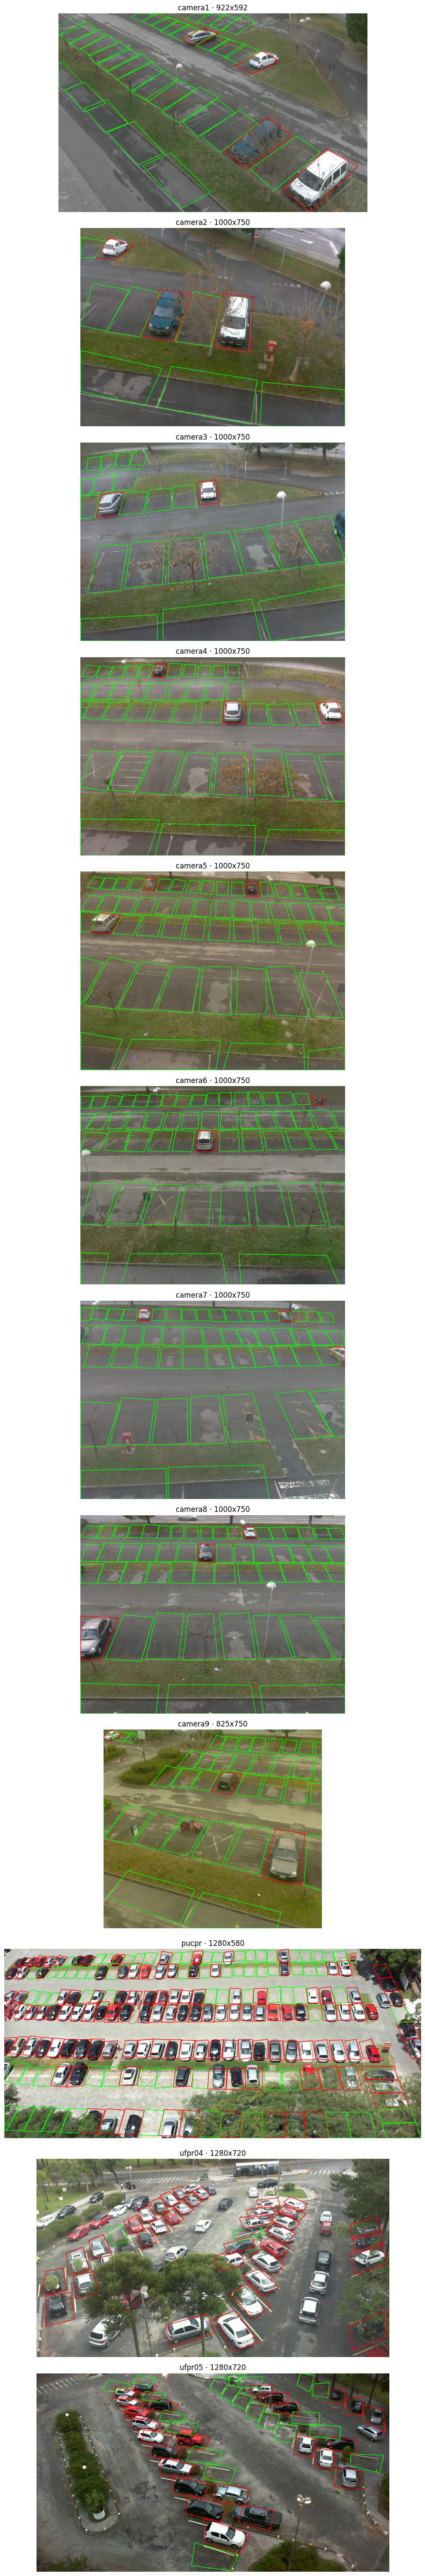

In [22]:
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from PIL import Image

COLORES = {1: 'lime', 2: 'red'}   # verde = libre, rojo = ocupada
anns_por_img = {}
for a in mini['annotations']:
    anns_por_img.setdefault(a['image_id'], []).append(a)

ejemplos = {}
for im in mini['images']:
    ejemplos.setdefault(im['subset'], im)

fig, axes = plt.subplots(len(ejemplos), 1, figsize=(10, 5 * len(ejemplos)), squeeze=False)
for ax, im in zip(axes[:, 0], ejemplos.values()):
    ax.imshow(Image.open(os.path.join(destino, im['file_name'])))
    for a in anns_por_img.get(im['id'], []):
        pts = list(zip(a['segmentation'][0][::2], a['segmentation'][0][1::2]))
        ax.add_patch(Polygon(pts, fill=False, edgecolor=COLORES[a['category_id']],
                             linewidth=1, linestyle='--' if a['truncated'] else '-'))
    ax.set_title(f"{im['subset']} · {im['width']}x{im['height']}")
    ax.axis('off')
plt.tight_layout()

Subir dataset a HuggingFace